# Homework 8.1 - Task 6

## Separation, Visible Bimodality, and Latent-Label Distinguishability

At $t=0$, consider the symmetric mixture

$$
\frac{1}{2}N(-a,\sigma_0^2)
+
\frac{1}{2}N(a,\sigma_0^2).
$$

The target separation is

$$
d=2a.
$$

We vary the dimensionless ratio

$$
r=\frac{d}{\sigma_0}.
$$

This separates the geometry from the units of the problem.

## 1. Visible bimodality threshold

The density has two distinct visible peaks exactly when

$$
a>\sigma_0.
$$

Since $d=2a$, this is equivalent to

$$
\frac{d}{\sigma_0}>2.
$$

At equality, the center is a flat single maximum.

Thus the visible-bimodality threshold is

$$
r=2.
$$

## 2. Statistical distinguishability of latent labels

Suppose the latent component label is known to be equally likely.

The optimal classifier uses the sign of $x$.

Its Bayes error is

$$
P_{error}
=
\Phi\left(
-\frac{a}{\sigma_0}
\right)
=
\Phi\left(
-\frac{r}{2}
\right).
$$

The corresponding optimal classification accuracy is

$$
1-P_{error}.
$$

There is no sharp classification threshold at $r=2$.

Label distinguishability improves gradually as the separation grows.

Therefore visible bimodality and statistical label distinguishability are different concepts.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import norm

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_1"

config = json.loads(
    (
        DATA_DIR
        / "task1_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

SIGMA0 = float(
    config["sigma0"]
)

RATIOS = np.array([
    0.5,
    1.0,
    1.5,
    2.0,
    2.5,
    3.0,
    4.0,
    6.0,
    8.0,
    16.0,
])

In [2]:
def mixture_density_initial(
    x,
    separation,
):
    a = (
        0.5
        * separation
    )

    return (
        0.5
        * norm.pdf(
            x,
            loc=-a,
            scale=SIGMA0,
        )
        + 0.5
        * norm.pdf(
            x,
            loc=a,
            scale=SIGMA0,
        )
    )

## 3. Numerical peak-count validation

In [3]:
rows = []

for ratio in RATIOS:
    separation = (
        ratio
        * SIGMA0
    )

    a = (
        0.5
        * separation
    )

    extent = max(
        5.0 * SIGMA0,
        a + 4.0 * SIGMA0,
    )

    x_grid = np.linspace(
        -extent,
        extent,
        100_001,
    )

    density = mixture_density_initial(
        x_grid,
        separation,
    )

    peaks, _ = find_peaks(
        density,
        prominence=1e-8,
    )

    analytic_two_peaks = (
        ratio > 2.0
    )

    bayes_error = float(
        norm.cdf(
            -0.5 * ratio
        )
    )

    rows.append({
        "separation_over_sigma": (
            ratio
        ),
        "separation": (
            separation
        ),
        "half_separation_a": (
            a
        ),
        "analytic_two_distinct_peaks": (
            analytic_two_peaks
        ),
        "numerical_peak_count": int(
            len(peaks)
        ),
        "bayes_label_error": (
            bayes_error
        ),
        "bayes_label_accuracy": (
            1.0
            - bayes_error
        ),
        "overlap_coefficient": (
            2.0
            * bayes_error
        ),
    })


separation_table = pd.DataFrame(
    rows
)

separation_path = (
    DATA_DIR
    / "task6_separation_bimodality_and_label_error.csv"
)

separation_table.to_csv(
    separation_path,
    index=False,
)

print(
    separation_table.to_string(
        index=False
    )
)

 separation_over_sigma  separation  half_separation_a  analytic_two_distinct_peaks  numerical_peak_count  bayes_label_error  bayes_label_accuracy  overlap_coefficient
                   0.5       0.125             0.0625                        False                     1       4.012937e-01              0.598706         8.025873e-01
                   1.0       0.250             0.1250                        False                     1       3.085375e-01              0.691462         6.170751e-01
                   1.5       0.375             0.1875                        False                     1       2.266274e-01              0.773373         4.532547e-01
                   2.0       0.500             0.2500                        False                     1       1.586553e-01              0.841345         3.173105e-01
                   2.5       0.625             0.3125                         True                     2       1.056498e-01              0.894350         2.112995e-0

## 4. Density shapes across the threshold

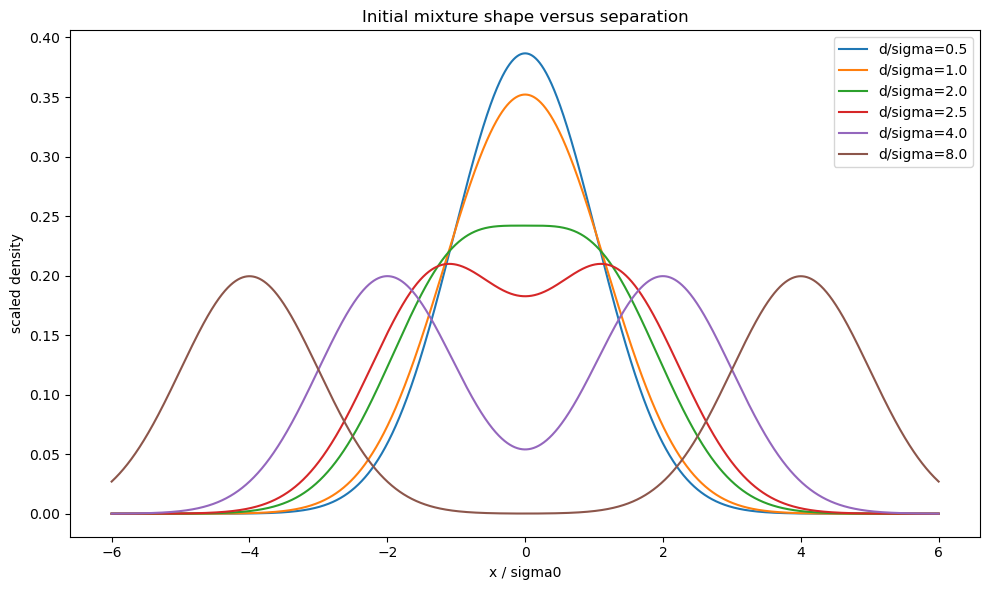

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task6_bimodality_vs_separation.png


In [4]:
selected_ratios = [
    0.5,
    1.0,
    2.0,
    2.5,
    4.0,
    8.0,
]

z_grid = np.linspace(
    -6.0,
    6.0,
    4000,
)

x_grid = (
    z_grid
    * SIGMA0
)

plt.figure(
    figsize=(10, 6)
)

for ratio in selected_ratios:
    separation = (
        ratio
        * SIGMA0
    )

    density = mixture_density_initial(
        x_grid,
        separation,
    )

    # Plot density in standardized horizontal units.
    plt.plot(
        z_grid,
        density
        * SIGMA0,
        label=f"d/sigma={ratio:.1f}",
    )

plt.xlabel("x / sigma0")
plt.ylabel("scaled density")
plt.title(
    "Initial mixture shape versus separation"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task6_bimodality_vs_separation.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

## 5. Label distinguishability versus visible bimodality

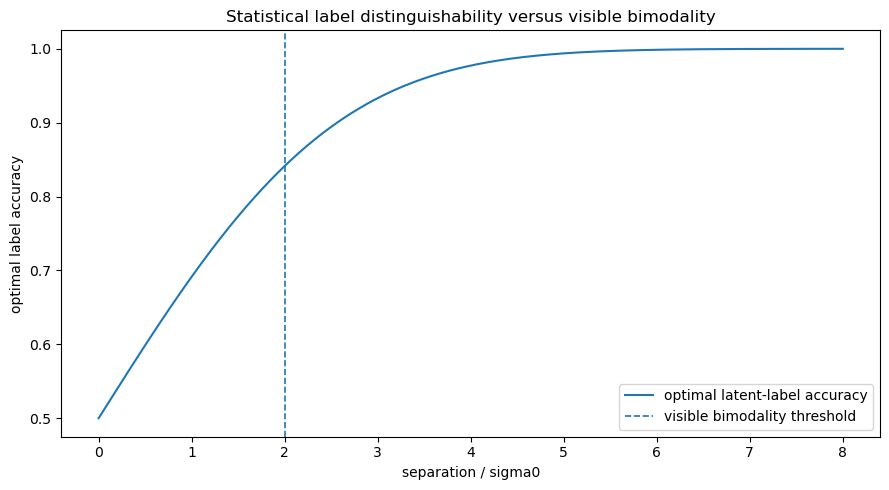

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task6_label_distinguishability.png


In [5]:
fine_ratios = np.linspace(
    0.0,
    8.0,
    500,
)

bayes_accuracy = (
    1.0
    - norm.cdf(
        -0.5
        * fine_ratios
    )
)

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    fine_ratios,
    bayes_accuracy,
    label="optimal latent-label accuracy",
)

plt.axvline(
    2.0,
    linestyle="--",
    linewidth=1.2,
    label="visible bimodality threshold",
)

plt.xlabel("separation / sigma0")
plt.ylabel("optimal label accuracy")
plt.title(
    "Statistical label distinguishability versus visible bimodality"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task6_label_distinguishability.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 6 Conclusion

The density becomes visibly bimodal only when

$$
d>2\sigma_0.
$$

Latent labels can already be statistically distinguishable before this threshold, and even after the threshold the Bayes error is nonzero at finite separation.

Thus:

- visible density peaks concern the geometry of the marginal density;
- latent-label distinguishability concerns statistical inference about the hidden component.

Task 7 replaces the exact score with a fitted neural approximation and evaluates both score error and generation error.